In [8]:
from sklearn import datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
iris = datasets.load_iris()
dir(iris)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [4]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [5]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [6]:
data=iris.data

In [ ]:
Y = iris.target

temp_arr = [0]*len(Y)

for i in range(len(Y)):
    if Y[i] == 0:
        temp_arr[i] = 'setosa'
    elif Y[i] == 1:
        temp_arr[i] = 'versicolor'
    else:
        temp_arr[i] = 'virginica'


#data variable is a numpy array. Converting it to pandas dataframe for better visualization
df = pd.DataFrame(data, columns=iris.feature_names)
df['target'] = temp_arr
df.head()

#data is features And Y is target variable

OneHotEncodedY = np.zeros((len(Y), 3))

for i in range(len(Y)):
    if Y[i] == 0:
        OneHotEncodedY[i][0] = 1
    elif Y[i] == 1:
        OneHotEncodedY[i][1] = 1
    else:
        OneHotEncodedY[i][2] = 1

print(OneHotEncodedY)        


[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]]


In [44]:
print('Class label counts:', np.bincount(Y))
print('X.shape:', data.shape)
print('Y.shape:', Y.shape)

# Shuffle + split (doğru yöntem: indeksleri başta alıp onlarla data'dan seçmek)
shuffle_idx = np.arange(Y.shape[0])
shuffle_rng = np.random.RandomState(123)
shuffle_rng.shuffle(shuffle_idx)

train_idx = shuffle_idx[:105]
test_idx  = shuffle_idx[105:]

X_train, X_test = data[train_idx], data[test_idx]
y_train, y_test = Y[train_idx], Y[test_idx]

# normalize using training statistics
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test  = (X_test - mu) / sigma

print('X_train.shape, X_test.shape:', X_train.shape, X_test.shape)
print('y_train bincount:', np.bincount(y_train))
print('y_test  bincount:', np.bincount(y_test))

Class label counts: [50 50 50]
X.shape: (150, 4)
Y.shape: (150,)
X_train.shape, X_test.shape: (105, 4) (45, 4)
y_train bincount: [37 32 36]
y_test  bincount: [13 18 14]


In [41]:


X_train.std(axis=0)



array([1., 1., 1., 1.])

## Adım adım açıklama
Aşağıdaki hücre eğitim verisini 3 sınıf için görselleştirir. Yapılan değişiklikler:
1. Sınıf etiketlerini dinamik olarak tespit etmek için `np.unique(y_train)` kullanıldı.
2. Her sınıf için farklı renk ve marker atamak üzere basit bir liste kullanıldı.
3. Kod, etiket sayısı 2 ya da 3 olduğunda da çalışacak şekilde genelleştirildi.

Bu hücreyi çalıştırdığınızda `X_train` ve `y_train` değişkenlerinin daha önce tanımlanmış ve normalize edilmiş olması gerekir.

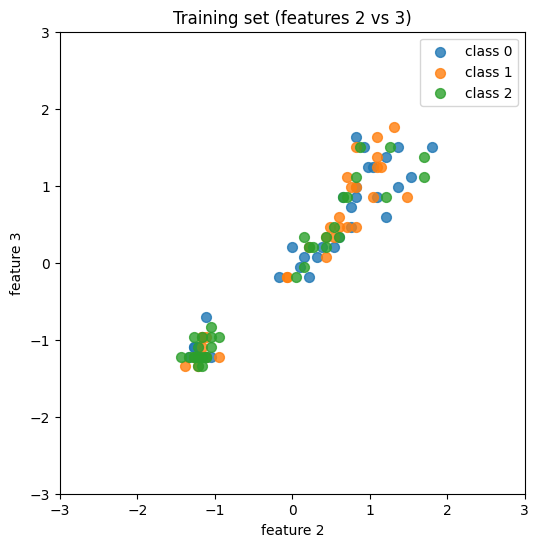

In [52]:
# İki feature ile görselleştirme
# Hangi feature'ları kullanmak isterseniz burayı değiştirin (index 0..3). Örnek: feature_a, feature_b = 0, 1
feature_a, feature_b = 2, 3  # <-- burayı değiştirin (örn 0,1 veya 2,3)
# feature isimleri için: print(iris.feature_names)
plt.figure(figsize=(6,6))
for cls in np.unique(y_train):
    mask = (y_train == cls)
    plt.scatter(X_train[mask, feature_a], X_train[mask, feature_b],
                label=f'class {int(cls)}', alpha=0.8, s=50)

plt.title(f'Training set (features {feature_a} vs {feature_b})')
plt.xlabel(f'feature {feature_a}')
plt.ylabel(f'feature {feature_b}')
plt.xlim([-3, 3])
plt.ylim([-3, 3])
plt.legend()
plt.show()

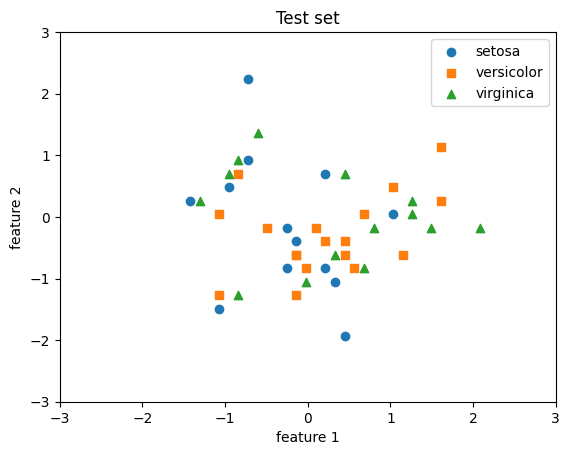

In [53]:
plt.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], label='setosa', marker='o')
plt.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], label='versicolor', marker='s')
plt.scatter(X_test[y_test==2, 0], X_test[y_test==2, 1], label='virginica', marker='^')
plt.title('Test set')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.xlim([-3, 3])
plt.ylim([-3, 3])
plt.legend()
plt.show()


In [ ]:
class Perceptron():
    def __init__(self, num_features):
        self.num_features = num_features
        self.weights = np.zeros((num_features, 1), dtype=np.float64) #değişecek
        self.bias = np.zeros(1, dtype=np.float64)#değişecek

    def forward(self, x):
        linear = np.dot(x, self.weights) + self.bias # comp. net input #değişebilir
        predictions = np.where(linear > 0., 1, 0)
        return predictions
        
    def backward(self, x, y):  
        predictions = self.forward(x)
        errors = y - predictions
        return errors
        
    def train(self, x, y, epochs):
        for e in range(epochs):
            
            for i in range(y.shape[0]):
                errors = self.backward(x[i].reshape(1, self.num_features), y[i]).reshape(-1)
                self.weights += (errors * x[i]).reshape(self.num_features, 1)
                self.bias += errors
                
    def evaluate(self, x, y):
        predictions = self.forward(x).reshape(-1)
        accuracy = np.sum(predictions == y) / y.shape[0]
        return accuracy


##############################################
# One-vs-Rest (OvR) için Perceptron modelleri oluşturma
##############################################



**Train**

In [34]:
ppn = Perceptron(num_features=4)

ppn.train(X_train, y_train, epochs=5)

print('Model parameters:\n\n')
print('  Weights: %s\n' % ppn.weights)
print('  Bias: %s\n' % ppn.bias)

Model parameters:


  Weights: [[-5.80933271]
 [-3.05009246]
 [ 5.3770216 ]
 [-5.32436766]]

  Bias: [22.]



In [35]:
train_acc = ppn.evaluate(X_train, y_train)
print('Train set accuracy: %.2f%%' % (train_acc*100))

Train set accuracy: 30.48%


In [36]:
test_acc = ppn.evaluate(X_test, y_test)
print('Test set accuracy: %.2f%%' % (test_acc*100))

Test set accuracy: 40.00%


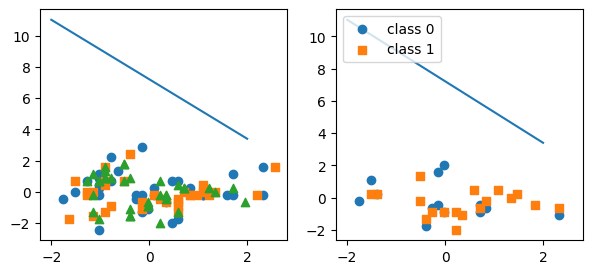

In [38]:
w, b = ppn.weights, ppn.bias

x0_min = -2
x1_min = ( (-(w[0] * x0_min) - b[0]) 
          / w[1] )

x0_max = 2
x1_max = ( (-(w[0] * x0_max) - b[0]) 
          / w[1] )

# x0*w0 + x1*w1 + b = 0
# x1  = (-x0*w0 - b) / w1


fig, ax = plt.subplots(1, 2, sharex=True, figsize=(7, 3))

ax[0].plot([x0_min, x0_max], [x1_min, x1_max])
ax[0].scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], label='class 0', marker='o')
ax[0].scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], label='class 1', marker='s')
ax[0].scatter(X_train[y_train==2, 0], X_train[y_train==2, 1], label='class 2', marker='^')

ax[1].plot([x0_min, x0_max], [x1_min, x1_max])
ax[1].scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], label='class 0', marker='o')
ax[1].scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], label='class 1', marker='s')

ax[1].legend(loc='upper left')
plt.show()
